In [1]:
#*************************** In-Class Assignment Sep 20*******************
#This assignment tests the skills of importing a dataset into a Python environment 
#and using the Pandas library and other Python functions to conduct basic data analysis.

#Total points: 20 

#Your code should answer each question and print them accordingly in your Jupyter Notebook.
#The code should be clean and readable with proper comments.
#The print statements and graphs should have appropriate names. Remove all unnecessary outcomes.

In [2]:
#Importing the Pandas library in the Python Notebook
#You do not need any other library for this project. Do not use any other library unless stated.
import pandas as pd

In [3]:
#Importing the data from your computer. 
#My Python code and the dataset are in the same folder, so I do not need to specify a directory. 
    #You may need to if you have them in different directories

data = pd.read_csv("weather_classification_data.csv")

#You can use .head() command to print the first n number of rows (by default 5 rows). 
#data.head()

#Now, the questions are attached next. Answer them in their blocks. Do not change the format of this file.

In [4]:
#Question 1: Print the number of rows and columns of this dataset (Points 1) 
print(data.shape)



(13200, 11)


In [5]:
#Question 2: Print all the column names of this dataset (Points 1)temperature, humidity, wind speed, precipitation, cloud cover, atmospheric pressure
print(data.columns)

Index(['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)',
       'Cloud Cover', 'Atmospheric Pressure', 'UV Index', 'Season',
       'Visibility (km)', 'Location', 'Weather Type'],
      dtype='object')


In [6]:
#Question 3: Print the unique values and their counts from the Season column (Points 1)
print(data["Season"].value_counts())

Winter    5610
Spring    2598
Autumn    2500
Summer    2492
Name: Season, dtype: int64


In [7]:
#Question 4: Print the mean, standard deviation, and variance of humidity variable (Points 1)
print(data["Humidity"].mean())
print(data["Humidity"].std())
print(data["Humidity"].var())


68.71083333333333
20.194248090636123
407.8076559461607


In [8]:
#Question 5: What are the mean, maximum, and minimum of each column against weather type? 
    #Show them. You may need to remove some columns for this operation.
#Drop columns that you don't want to include in the groupby operation. 
#Show mean, max, and min in separate blocks. (Points 2)
numeric_data = data.drop(columns=["Season", "Location"])
print(numeric_data.groupby("Weather Type").mean())

              Temperature   Humidity  Wind Speed  Precipitation (%)  \
Weather Type                                                          
Cloudy          22.823636  66.528788    8.601818          40.286364   
Rainy           22.788182  78.397879   13.677576          74.752424   
Snowy           -1.530606  78.510303   10.976212          74.586061   
Sunny           32.429091  51.406364    6.073182          24.952727   

              Atmospheric Pressure  UV Index  Visibility (km)  
Weather Type                                                   
Cloudy                 1010.170724  3.583939         7.071212  
Rainy                  1004.149848  2.684242         3.628485  
Snowy                   991.051842  1.950303         3.591515  
Sunny                  1017.939170  7.804545         7.560455  


In [9]:
#Question 6: Filter data for a Spring season and calculate total precipitation (Points 2)
# Use '==' for comparison
spring_data = data[data["Season"] == "Spring"]
print(spring_data["Precipitation (%)"].sum())

120504.0


In [10]:
#Question 7: Create a subset of the data where the temperature is above 32°C, the wind speed is below 5 m/s, 
    #and the UV index is greater than 7. 

#Calculate the average atmospheric pressure and the most common weather type for this subset. (Points 2)
subset = data[
    (data["Temperature"] >32) &
    (data["Wind Speed"] < 5) &
    (data["UV Index"] > 7)
    ]
print("Average Atmospheric Pressure:", subset["Atmospheric Pressure"].mean())
print("Most Common Weather Type:", subset["Weather Type"].mode()[0])


Average Atmospheric Pressure: 1017.5631840796016
Most Common Weather Type: Sunny


In [11]:
#Question 8: Print the 5 days with the highest temperatures and the corresponding humidity, wind speed, and season.
top5 = data.nlargest(5, "Temperature")
print(top5[["Temperature", "Humidity", "Wind Speed", "Season"]])

       Temperature  Humidity  Wind Speed  Season
5085         109.0        89         3.0  Spring
10993        108.0        77        10.0  Summer
2958         107.0        78         8.5  Winter
8353         107.0       107        15.0  Summer
9328         102.0        99         2.0  Winter


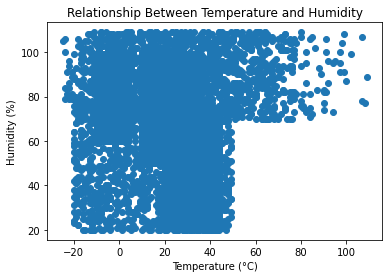

In [12]:
#*********From here, you will use the Matplotlib library to generate some plots. (Points 3)
#Question 1: Show the relationship between temperature and humidity using an appropriate plot. Give proper axis and plot titles.

import matplotlib.pyplot as plt #You import only once in your notebook. However, if you restart the kernel, you will need to do it again.
plt.scatter(data["Temperature"], data ["Humidity"])
plt.xlabel("Temperature (°C)")
plt.ylabel("Humidity (%)")
plt.title("Relationship Between Temperature and Humidity")
plt.show()

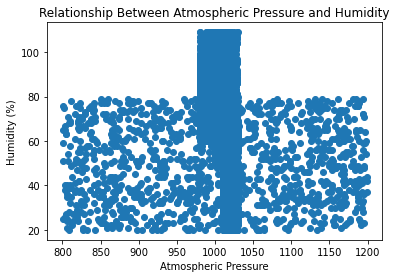

In [13]:
#Question 2: Visually display the correlation between Atmospheric Pressure vs. Humidity (Points 2)

plt.scatter(data["Atmospheric Pressure"], data ["Humidity"])
plt.xlabel("Atmospheric Pressure")
plt.ylabel("Humidity (%)")
plt.title("Relationship Between Atmospheric Pressure and Humidity")
plt.show()

In [14]:
#Question 3: You created a plot for two variables. Now, generate a pair-wise correlation plot for 
    #UV Index vs. Temperature vs. Wind Speed vs. Humidity. 
#It will be a grid-like system. I pasted the plot below for your reference. 
    #Feel free to reproduce it or develop your own (preferred). (Points 3)



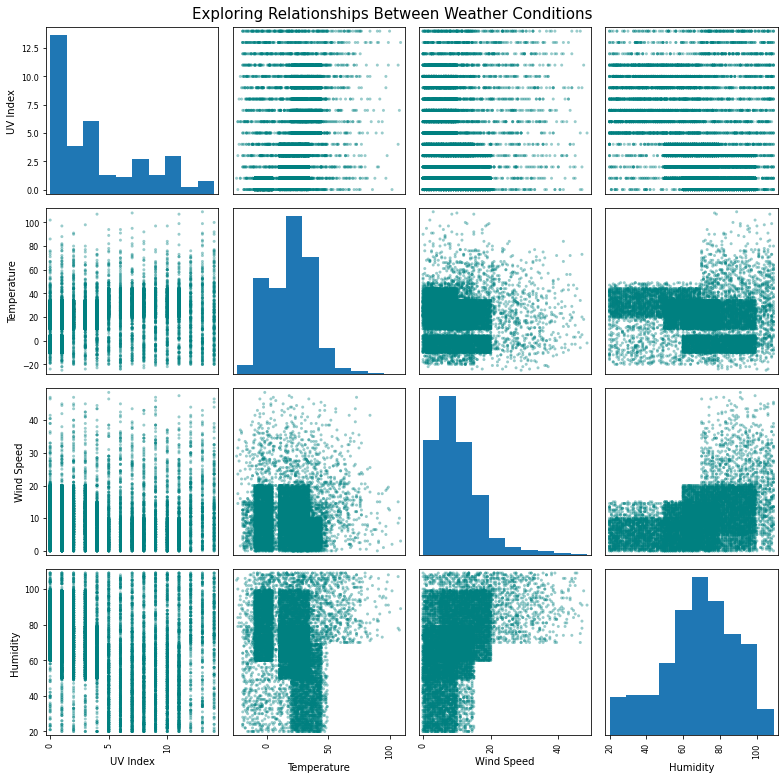

In [15]:
from pandas.plotting import scatter_matrix

weather = data[["UV Index", "Temperature", "Wind Speed", "Humidity"]]

axes = scatter_matrix(
    weather,
    figsize=(11, 11),
    diagonal="hist",
    color="teal",
    alpha=0.4,
    marker="."
)

plt.suptitle("Exploring Relationships Between Weather Conditions", fontsize=15)
plt.tight_layout()
plt.show()
    

In [16]:
#Question 4: Generate the histogram of UV index. What do you think? Does it show normality? Can you make it closer to normal?
#Hint: You may import the math library. (Points 2)

# Use the library below for any transformation
import math

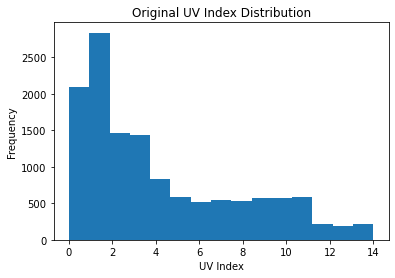

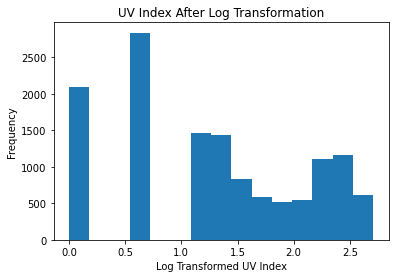

In [17]:
plt.hist(data["UV Index"], bins=15)
plt.xlabel("UV Index")
plt.ylabel("Frequency")
plt.title("Original UV Index Distribution")
plt.show()

plt.hist(data["UV Index"].apply(math.log1p), bins=15)
plt.xlabel("Log Transformed UV Index")
plt.ylabel("Frequency")
plt.title("UV Index After Log Transformation")
plt.show()

# The original UV Index is right-skewed and not normally distributed.
# I tried a log transformation to make it closer to normal.
# However, the transformed data still does not look bell-shaped.
# The log transformation did not achieve normality.